# 04 — State Characterization and Task Relationships

Notebook 03 fitted the TDE-HMM and saved the state dictionary plus
per-subject state time courses. This notebook does two things:

1. **Characterize** the discovered states in sensor space — their
   spectral profiles and their spatial topographies.
2. **Relate** state dynamics to the experimental variables: task phase,
   cognitive load, response accuracy, and reaction time.

**Methodological discipline.** The state dictionary was frozen in
notebook 03 without any access to labels. Labels are revealed for the
first time here. Any relationship we report between state dynamics and
task variables is therefore *discovered*, not imposed.

**Sensor-space interpretation.** EEG topographies reflect scalp
potential distributions. A state with a frontocentral scalp pattern is
consistent with activity over frontal and central regions, but this does
not by itself establish a cortical network or generator without source
localization.

**Reference method.** State characterization follows Quinn et al. (2018,
*Front. Neurosci.*): evoked fractional occupancy, aligned across trials,
analyzed against baseline. State-resolved spectral characterization
follows the OHBA TDE-HMM literature (Vidaurre et al. 2016, *NeuroImage*;
osl-dynamics toolbox).

In [1]:
# Setup for notebook 04.
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = REPO_ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

from eeg_state import config, model
from eeg_state.io import load_events, reconstruct_trials

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

TRIAL_DURATION_S = 5.0

# Load the frozen model artifacts from notebook 03.
with open(config.RESULTS / "models" / "tde_hmm_model.pkl", "rb") as f:
    artifacts = pickle.load(f)

K = artifacts["n_states"]
print(f"Loaded model: K={K}, N_PCS={artifacts['n_pcs']}, "
      f"tde lags={artifacts['tde_lags'][0]}..{artifacts['tde_lags'][-1]}")
print(f"Development subjects: {artifacts['dev_subjects']}")


def iterate_trials(subject, artifacts):
    """Yield (eeg_segment, posteriors) for each trial.

    EEG is TDE-trimmed to align with the state time course: if the raw
    trial is n samples, the embedded trial is n - 2*|max_lag| samples.
    Trimming removes the first and last |max_lag| samples to match.
    """
    fs = artifacts["target_sfreq"]
    trim = abs(artifacts["tde_lags"][0])
    n_samples = int(TRIAL_DURATION_S * fs)

    raw = mne.io.read_raw_fif(
        config.DATA_DERIV / subject / f"{subject}_preprocessed_raw.fif",
        preload=True, verbose="ERROR",
    )
    data = raw.get_data() * 1e6  # V -> uV
    trials_df = reconstruct_trials(load_events(subject))
    npz = np.load(config.DATA_DERIV / subject / f"{subject}_states.npz")
    posteriors = npz["posteriors"]
    lengths = npz["lengths"]

    cursor = 0
    for _, t in trials_df.iterrows():
        start = int(t["encoding_onset_s"] * fs)
        end = start + n_samples
        if end > data.shape[1]:
            cursor += 1
            continue
        L = int(lengths[cursor]) if cursor < len(lengths) else 0
        if L <= 0:
            cursor += 1
            continue
        eeg = data[:, start + trim : start + trim + L]
        post = posteriors[cursor : cursor + L]
        yield eeg, post
        cursor += 1


print("Helpers ready.")

Loaded model: K=2, N_PCS=20, tde lags=-7..7
Development subjects: ['sub-04', 'sub-05', 'sub-10', 'sub-11', 'sub-17', 'sub-24', 'sub-34', 'sub-45']
Helpers ready.


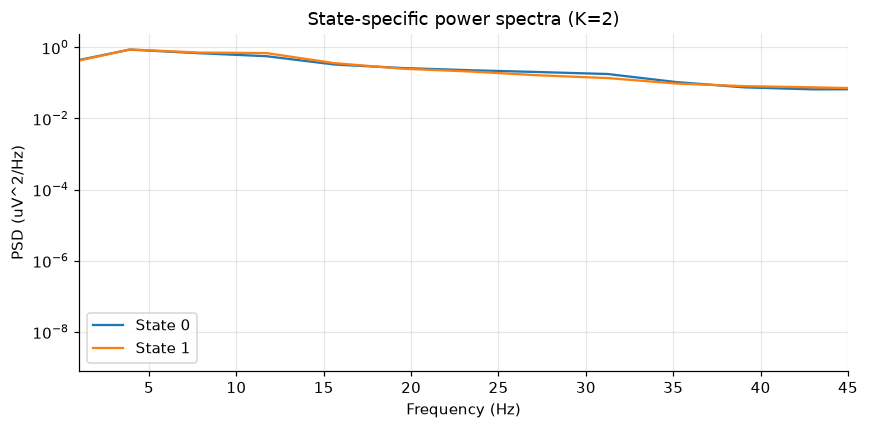

        state 0   state 1
delta  0.865228  0.873346
theta  0.687821  0.715553
alpha  0.564603  0.691492
beta   0.239687  0.224005
gamma  0.082357  0.084247


In [2]:
# Compute per-state PSD using windowed FFT weighted by state posteriors.
# Window length 64 samples (256 ms) balances spectral resolution against
# state dwell time. Soft (posterior) weighting lets windows with mixed
# states contribute proportionally.

def compute_state_spectra(subjects, artifacts, win_len=64, hop=32):
    fs = artifacts["target_sfreq"]
    K = artifacts["n_states"]
    psd_sum, weight_sum = None, None
    f = None

    for sub in subjects:
        for eeg, post in iterate_trials(sub, artifacts):
            L = eeg.shape[1]
            for w in range(0, L - win_len + 1, hop):
                seg = eeg[:, w : w + win_len]
                wp = post[w : w + win_len].mean(axis=0)
                seg = seg - seg.mean(axis=1, keepdims=True)
                taper = np.hanning(win_len)
                fft = np.fft.rfft(seg * taper, axis=1)
                pxx = (np.abs(fft) ** 2) * 2 / (fs * np.sum(taper ** 2))

                if psd_sum is None:
                    f = np.fft.rfftfreq(win_len, d=1.0 / fs)
                    psd_sum = np.zeros((K, pxx.shape[0], len(f)))
                    weight_sum = np.zeros(K)
                for k in range(K):
                    psd_sum[k] += wp[k] * pxx
                    weight_sum[k] += wp[k]

    return f, psd_sum / np.maximum(weight_sum[:, None, None], 1e-10)


f, psd = compute_state_spectra(config.DEV_SUBJECTS, artifacts)

fig, ax = plt.subplots(figsize=(8, 4))
for k in range(K):
    p = psd[k].mean(axis=0)  # channel-averaged
    ax.semilogy(f, p, label=f"State {k}", linewidth=1.5)
ax.set_xlabel("Frequency (Hz)")
ax.set_ylabel("PSD (uV^2/Hz)")
ax.set_xlim(1, 45)
ax.set_title(f"State-specific power spectra (K={K})")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Print band-power ratios for the key bands, useful for the markdown.
bands = {
    "delta": (0.1, 4.0),      # bin 3.906
    "theta": (4.0, 8.0),      # bin 7.812
    "alpha": (8.0, 12.0),     # bin 11.719
    "beta":  (12.0, 32.0),    # bins 15.625, 19.531, 23.438, 27.344, 31.25
    "gamma": (32.0, 45.0),    # bins 35.156, 39.062, 42.969
}
df = pd.DataFrame(index=list(bands.keys()), columns=[f"state {k}" for k in range(K)])
for name, (lo, hi) in bands.items():
    mask = (f >= lo - 1e-6) & (f <= hi + 1e-6)
    for k in range(K):
        df.loc[name, f"state {k}"] = psd[k][:, mask].mean()
print(df.round(4))

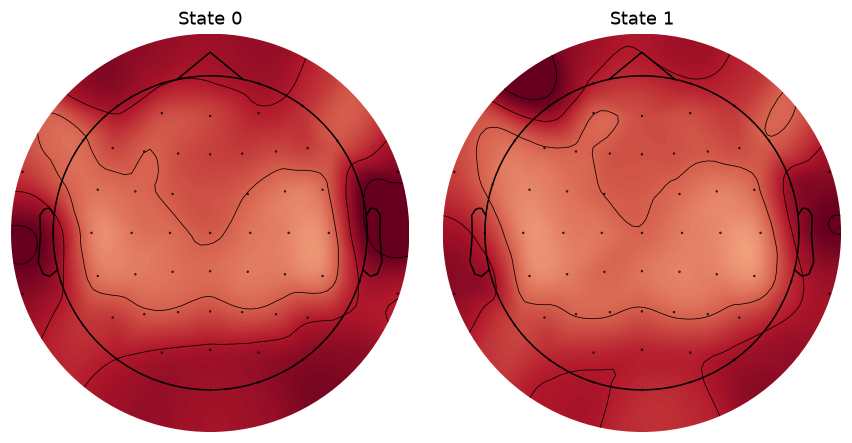

State 0 top-5 channels: [('T8', 7.547), ('FT10', 7.136), ('FT8', 7.108), ('TP9', 6.93), ('PO8', 6.842)]
State 1 top-5 channels: [('AF7', 7.006), ('TP9', 6.763), ('FT10', 6.738), ('FT8', 6.488), ('T8', 6.454)]


In [3]:
# Per-state scalp power map, averaged across subjects.
# For each state, select the samples assigned to that state (hard Viterbi
# assignment) and compute the RMS amplitude per channel.

def compute_state_topography(subjects, artifacts):
    K = artifacts["n_states"]
    topo_sum = np.zeros((K, 63))
    n_subj = 0

    for sub in subjects:
        npz = np.load(config.DATA_DERIV / sub / f"{sub}_states.npz")
        viterbi = npz["viterbi"]
        # Recompute trial bounds to align viterbi with EEG
        fs = artifacts["target_sfreq"]
        trim = abs(artifacts["tde_lags"][0])
        n_samples = int(TRIAL_DURATION_S * fs)

        raw = mne.io.read_raw_fif(
            config.DATA_DERIV / sub / f"{sub}_preprocessed_raw.fif",
            preload=True, verbose="ERROR")
        data = raw.get_data() * 1e6
        trials_df = reconstruct_trials(load_events(sub))
        lengths = npz["lengths"]

        sub_sq = np.zeros((K, 63))
        sub_n = np.zeros(K)
        cursor = 0
        for _, t in trials_df.iterrows():
            start = int(t["encoding_onset_s"] * fs)
            if start + n_samples > data.shape[1] or cursor >= len(lengths):
                continue
            L = int(lengths[cursor])
            eeg = data[:, start + trim : start + trim + L]
            seg_v = viterbi[cursor : cursor + L]
            for k in range(K):
                m = seg_v == k
                if m.any():
                    sub_sq[k] += np.sum(eeg[:, m] ** 2, axis=1)
                    sub_n[k] += m.sum()
            cursor += 1

        for k in range(K):
            if sub_n[k] > 0:
                topo_sum[k] += np.sqrt(sub_sq[k] / sub_n[k])
        n_subj += 1

    return topo_sum / n_subj


topo = compute_state_topography(config.DEV_SUBJECTS, artifacts)

# Reuse the info from a preprocessed file for the montage.
raw0 = mne.io.read_raw_fif(
    config.DATA_DERIV / config.DEV_SUBJECTS[0]
    / f"{config.DEV_SUBJECTS[0]}_preprocessed_raw.fif",
    preload=False, verbose="ERROR")

fig, axes = plt.subplots(1, K, figsize=(4 * K, 4))
if K == 1:
    axes = [axes]
vmax = np.abs(topo).max()
for k, ax in enumerate(axes):
    im, _ = mne.viz.plot_topomap(
        topo[k], raw0.info, axes=ax, show=False,
        cmap="RdBu_r", vlim=(-vmax, vmax), contours=4,
    )
    ax.set_title(f"State {k}")
plt.tight_layout()
plt.show()

# Quantify: which channels are strongest in each state?
ch_names = raw0.ch_names
for k in range(K):
    idx = np.argsort(np.abs(topo[k]))[::-1][:5]
    print(f"State {k} top-5 channels: "
          f"{[(ch_names[i], round(float(topo[k][i]), 3)) for i in idx]}")

In [4]:
# Spatial correlation between state topographies.
r = np.corrcoef(topo[0], topo[1])[0, 1]
print(f"Spatial correlation between state 0 and state 1 topographies: {r:.3f}")
print(f"Amplitude ratio (max channel): "
      f"{np.abs(topo[1]).max() / np.abs(topo[0]).max():.2f}")

Spatial correlation between state 0 and state 1 topographies: 0.959
Amplitude ratio (max channel): 0.93


In [5]:
print("State means in PCA space (20 PCs):")
print(artifacts["hmm"].means_.round(3))
print("\nComponent-wise difference (state 1 - state 0):")
print((artifacts["hmm"].means_[1] - artifacts["hmm"].means_[0]).round(3))
print("\nCovariance traces:")
for k in range(2):
    print(f"  state {k}: trace = {np.trace(artifacts['hmm'].covars_[k]):.3f}")

State means in PCA space (20 PCs):
[[ 0.012  0.027 -0.021  0.033 -0.097 -0.076  0.112  0.062  0.048 -0.133
  -0.024  0.158 -0.008  0.02  -0.062  0.048  0.048  0.095  0.003  0.027]
 [-0.001 -0.002  0.001 -0.002  0.006  0.005 -0.007 -0.004 -0.003  0.008
   0.002 -0.01   0.001 -0.001  0.004 -0.003 -0.003 -0.006 -0.    -0.002]]

Component-wise difference (state 1 - state 0):
[-0.013 -0.029  0.023 -0.035  0.103  0.081 -0.119 -0.066 -0.051  0.141
  0.025 -0.168  0.009 -0.021  0.066 -0.051 -0.051 -0.101 -0.003 -0.028]

Covariance traces:
  state 0: trace = 81.725
  state 1: trace = 16.058
